# TQQQ Drawdown-to-Peak Mean Reversion Backtest

This notebook tests a simple rule on the last ~15 years of TQQQ daily data: 
buy when price drops to a given percentage of the most recent peak, 
then hold until price returns to that peak.

Thresholds tested: 50%, 60%, 70%, 80%, 90% of the last peak.


In [12]:
import warnings

import numpy as np
import pandas as pd
import yfinance as yf

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.4f}'.format)


In [13]:
# Pandas display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)


In [14]:
# Parameters
symbol = 'TQQQ'
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]

end_date = pd.Timestamp.today().normalize()
start_date = end_date - pd.DateOffset(years=15)
start_date, end_date


(Timestamp('2011-02-02 00:00:00'), Timestamp('2026-02-02 00:00:00'))

In [15]:
# Download data (adjusted close)
data = yf.download(symbol, start=start_date, end=end_date, auto_adjust=True, progress=False)
if data.empty:
    raise ValueError('No data downloaded. Check your network or symbol.')
prices = data['Close']
# If multiple columns returned, select the symbol column or the first column
if isinstance(prices, pd.DataFrame):
    if symbol in prices.columns:
        prices = prices[symbol]
    else:
        prices = prices.iloc[:, 0]
prices = prices.dropna()
prices.head()


Date
2011-02-02   0.4171
2011-02-03   0.4187
2011-02-04   0.4263
2011-02-07   0.4324
2011-02-08   0.4417
Name: TQQQ, dtype: float64

In [16]:
def strategy_metrics(prices: pd.Series, threshold: float) -> pd.Series:
    # Daily equity curve metrics (includes out-of-market time)
    if isinstance(prices, pd.DataFrame):
        if prices.shape[1] == 1:
            prices = prices.iloc[:, 0]
        else:
            prices = prices.iloc[:, 0]
    prices = pd.Series(prices).dropna()

    peak = prices.iloc[0]
    in_trade = False
    entry_price = None
    peak_at_entry = None

    equity_at_entry = 1.0
    current_equity = 1.0
    equity = []
    position = []

    for dt, price in prices.items():
        if not in_trade:
            if price > peak:
                peak = price
            if price <= peak * threshold:
                in_trade = True
                entry_price = price
                peak_at_entry = peak
                equity_at_entry = current_equity
        else:
            current_equity = equity_at_entry * (price / entry_price)
            if price >= peak_at_entry:
                in_trade = False
                equity_at_entry = current_equity
                peak = price

        if in_trade:
            current_equity = equity_at_entry * (price / entry_price)
            position.append(1)
        else:
            current_equity = equity_at_entry
            position.append(0)

        equity.append(current_equity)

    equity = pd.Series(equity, index=prices.index)
    position = pd.Series(position, index=prices.index)
    daily_ret = equity.pct_change().fillna(0.0)

    period_days = (prices.index[-1] - prices.index[0]).days
    years = period_days / 365.25 if period_days > 0 else np.nan

    total_multiple = equity.iloc[-1] / equity.iloc[0] if equity.iloc[0] != 0 else np.nan
    cagr = (total_multiple ** (1.0 / years) - 1.0) if years and years > 0 else np.nan

    eq_peak = equity.cummax()
    drawdown = equity / eq_peak - 1.0
    max_dd = drawdown.min()

    ann_vol = daily_ret.std(ddof=0) * np.sqrt(252)
    ann_ret = daily_ret.mean() * 252
    sharpe = (ann_ret / ann_vol) if ann_vol and not np.isnan(ann_vol) else np.nan

    time_in_mkt = position.mean()

    return pd.Series({
        'strategy_total_multiple': total_multiple,
        'strategy_cagr': cagr,
        'strategy_ann_vol': ann_vol,
        'strategy_sharpe_0rf': sharpe,
        'strategy_max_drawdown': max_dd,
        'time_in_market': time_in_mkt,
    })


In [17]:
def backtest_threshold(prices: pd.Series, threshold: float) -> pd.DataFrame:
    # Coerce to 1D Series
    if isinstance(prices, pd.DataFrame):
        if prices.shape[1] == 1:
            prices = prices.iloc[:, 0]
        else:
            prices = prices.iloc[:, 0]
    prices = pd.Series(prices).dropna()

    peak = prices.iloc[0]
    in_trade = False
    trades = []

    entry_date = None
    entry_price = None
    peak_at_entry = None

    for dt, price in prices.items():
        if not in_trade:
            if price > peak:
                peak = price
            if price <= peak * threshold:
                in_trade = True
                entry_date = dt
                entry_price = price
                peak_at_entry = peak
        else:
            if price >= peak_at_entry:
                exit_date = dt
                exit_price = price
                trades.append({
                    'threshold': threshold,
                    'entry_date': entry_date,
                    'entry_price': entry_price,
                    'peak_price': peak_at_entry,
                    'exit_date': exit_date,
                    'exit_price': exit_price,
                    'closed': True,
                })
                in_trade = False
                peak = price

    if in_trade:
        trades.append({
            'threshold': threshold,
            'entry_date': entry_date,
            'entry_price': entry_price,
            'peak_price': peak_at_entry,
            'exit_date': prices.index[-1],
            'exit_price': prices.iloc[-1],
            'closed': False,
        })

    df = pd.DataFrame(trades)
    if df.empty:
        return df
    df['return_multiple'] = df['exit_price'] / df['entry_price']
    df['return_pct'] = df['return_multiple'] - 1.0
    df['hold_days'] = (df['exit_date'] - df['entry_date']).dt.days
    return df


In [18]:
def summarize_trades(trades: pd.DataFrame, prices: pd.Series) -> pd.Series:
    if trades.empty:
        return pd.Series(dtype='float64')

    closed = trades[trades['closed']]
    open_trades = trades[~trades['closed']]

    period_years = (prices.index[-1] - prices.index[0]).days / 365.25

    if not closed.empty:
        total_multiple = closed['return_multiple'].prod()
        avg_multiple = closed['return_multiple'].mean()
        median_multiple = closed['return_multiple'].median()
        std_multiple = closed['return_multiple'].std(ddof=0)
        best_multiple = closed['return_multiple'].max()
        worst_multiple = closed['return_multiple'].min()
        avg_return_pct = closed['return_pct'].mean()
        median_return_pct = closed['return_pct'].median()
        win_rate = (closed['return_multiple'] > 1.0).mean()
        avg_hold = closed['hold_days'].mean()
        median_hold = closed['hold_days'].median()
        max_hold = closed['hold_days'].max()
        min_hold = closed['hold_days'].min()
        trade_freq = len(closed) / period_years
    else:
        total_multiple = np.nan
        avg_multiple = np.nan
        median_multiple = np.nan
        std_multiple = np.nan
        best_multiple = np.nan
        worst_multiple = np.nan
        avg_return_pct = np.nan
        median_return_pct = np.nan
        win_rate = np.nan
        avg_hold = np.nan
        median_hold = np.nan
        max_hold = np.nan
        min_hold = np.nan
        trade_freq = 0.0

    unrealized_multiple = open_trades['return_multiple'].iloc[0] if not open_trades.empty else np.nan
    close_rate = len(closed) / len(trades) if len(trades) > 0 else np.nan

    return pd.Series({
        'trades_total': len(trades),
        'trades_closed': len(closed),
        'trades_open': len(open_trades),
        'close_rate': close_rate,
        'trades_per_year': trade_freq,
        'avg_return_multiple': avg_multiple,
        'median_return_multiple': median_multiple,
        'return_multiple_std': std_multiple,
        'best_return_multiple': best_multiple,
        'worst_return_multiple': worst_multiple,
        'avg_return_pct': avg_return_pct,
        'median_return_pct': median_return_pct,
        'win_rate': win_rate,
        'total_multiple_closed': total_multiple,
        'total_return_pct_closed': (total_multiple - 1.0) if pd.notna(total_multiple) else np.nan,
        'avg_hold_days': avg_hold,
        'median_hold_days': median_hold,
        'max_hold_days': max_hold,
        'min_hold_days': min_hold,
        'unrealized_multiple': unrealized_multiple,
    })


In [19]:
# Run backtests
all_trades = []
summaries = []

for th in thresholds:
    t = backtest_threshold(prices, th)
    if not t.empty:
        all_trades.append(t)
    s = summarize_trades(t, prices)
    m = strategy_metrics(prices, th)
    s = pd.concat([s, m])
    s['threshold'] = th
    summaries.append(s)

trades_df = pd.concat(all_trades, ignore_index=True) if all_trades else pd.DataFrame()
trade_col_map = {
    'threshold': 'threshold',
    'entry_date': 'entry_date',
    'entry_price': 'entry_price',
    'peak_price': 'peak_price',
    'exit_date': 'exit_date',
    'exit_price': 'exit_price',
    'closed': 'closed',
    'return_multiple': 'return_multiple',
    'return_pct': 'return_pct',
    'hold_days': 'hold_days',
}
if not trades_df.empty:
    trades_df = trades_df.rename(columns=trade_col_map)

summary_df = pd.DataFrame(summaries).set_index('threshold').sort_index()
summary_df


,trades_total,trades_closed,trades_open,close_rate,trades_per_year,avg_return_multiple,median_return_multiple,return_multiple_std,best_return_multiple,worst_return_multiple,avg_return_pct,median_return_pct,win_rate,total_multiple_closed,total_return_pct_closed,avg_hold_days,median_hold_days,max_hold_days,min_hold_days,unrealized_multiple,strategy_total_multiple,strategy_cagr,strategy_ann_vol,strategy_sharpe_0rf,strategy_max_drawdown,time_in_market
threshold,,,,,,,,,,,,,,,,,,,,,,,,,,
0.5000,4.0000,4.0000,0.0000,1.0000,0.2668,2.3121,2.2613,0.2053,2.6396,2.0860,1.3121,1.2613,1.0000,28.1425,27.1425,392.7500,224.0000,"1,003.0000",120.0000,NaN,28.1425,0.2493,0.3974,0.7596,-0.7404,0.2864
0.6000,6.0000,6.0000,0.0000,1.0000,0.4002,1.7811,1.7320,0.0922,1.9296,1.6930,0.7811,0.7320,1.0000,31.6698,30.6698,343.1667,207.0000,"1,042.0000",123.0000,NaN,31.6698,0.2592,0.4569,0.7354,-0.7482,0.3758
0.7000,10.0000,10.0000,0.0000,1.0000,0.6670,1.5178,1.4705,0.0839,1.6930,1.4401,0.5178,0.4705,1.0000,63.9429,62.9429,270.7000,161.0000,"1,049.0000",36.0000,NaN,63.9429,0.3196,0.5119,0.8008,-0.7482,0.4946
0.8000,19.0000,18.0000,1.0000,0.9474,1.2006,1.3134,1.2963,0.0523,1.4492,1.2572,0.3134,0.2963,1.0000,133.3814,132.3814,172.9444,91.5000,"1,056.0000",18.0000,1.1644,155.3040,0.4001,0.5418,0.8961,-0.7740,0.5813
0.9000,33.0000,32.0000,1.0000,0.9697,2.1344,1.1526,1.1461,0.0254,1.2348,1.1192,0.1526,0.1461,1.0000,93.3218,92.3218,116.1875,42.5000,"1,099.0000",6.0000,1.0120,94.4385,0.3544,0.5763,0.8189,-0.8126,0.6950


In [20]:
# Simple ranking: higher total multiple + higher trade frequency
rank_df = summary_df.copy()
rank_df['score'] = rank_df['total_multiple_closed'].rank(ascending=False) + \
                           rank_df['trades_per_year'].rank(ascending=False)
rank_df.sort_values('score', ascending=False)


,trades_total,trades_closed,trades_open,close_rate,trades_per_year,avg_return_multiple,median_return_multiple,return_multiple_std,best_return_multiple,worst_return_multiple,avg_return_pct,median_return_pct,win_rate,total_multiple_closed,total_return_pct_closed,avg_hold_days,median_hold_days,max_hold_days,min_hold_days,unrealized_multiple,strategy_total_multiple,strategy_cagr,strategy_ann_vol,strategy_sharpe_0rf,strategy_max_drawdown,time_in_market,score
threshold,,,,,,,,,,,,,,,,,,,,,,,,,,,
0.5000,4.0000,4.0000,0.0000,1.0000,0.2668,2.3121,2.2613,0.2053,2.6396,2.0860,1.3121,1.2613,1.0000,28.1425,27.1425,392.7500,224.0000,"1,003.0000",120.0000,NaN,28.1425,0.2493,0.3974,0.7596,-0.7404,0.2864,10.0000
0.6000,6.0000,6.0000,0.0000,1.0000,0.4002,1.7811,1.7320,0.0922,1.9296,1.6930,0.7811,0.7320,1.0000,31.6698,30.6698,343.1667,207.0000,"1,042.0000",123.0000,NaN,31.6698,0.2592,0.4569,0.7354,-0.7482,0.3758,8.0000
0.7000,10.0000,10.0000,0.0000,1.0000,0.6670,1.5178,1.4705,0.0839,1.6930,1.4401,0.5178,0.4705,1.0000,63.9429,62.9429,270.7000,161.0000,"1,049.0000",36.0000,NaN,63.9429,0.3196,0.5119,0.8008,-0.7482,0.4946,6.0000
0.8000,19.0000,18.0000,1.0000,0.9474,1.2006,1.3134,1.2963,0.0523,1.4492,1.2572,0.3134,0.2963,1.0000,133.3814,132.3814,172.9444,91.5000,"1,056.0000",18.0000,1.1644,155.3040,0.4001,0.5418,0.8961,-0.7740,0.5813,3.0000
0.9000,33.0000,32.0000,1.0000,0.9697,2.1344,1.1526,1.1461,0.0254,1.2348,1.1192,0.1526,0.1461,1.0000,93.3218,92.3218,116.1875,42.5000,"1,099.0000",6.0000,1.0120,94.4385,0.3544,0.5763,0.8189,-0.8126,0.6950,3.0000


In [21]:
# Inspect trades for a chosen threshold (example: 0.7)
trades_df[trades_df['threshold'] == 0.7]


,threshold,entry_date,entry_price,peak_price,exit_date,exit_price,closed,return_multiple,return_pct,hold_days
10,0.7000,2011-08-08,0.2780,0.4641,2012-02-08,0.4706,True,1.6930,0.6930,184
11,0.7000,2012-05-18,0.4279,0.6129,2012-09-06,0.6237,True,1.4577,0.4577,111
12,0.7000,2012-11-14,0.4449,0.6473,2013-04-30,0.6480,True,1.4568,0.4568,167
13,0.7000,2015-08-24,1.6117,2.5340,2016-09-22,2.5859,True,1.6045,0.6045,395
14,0.7000,2018-10-24,5.8382,8.6523,2019-11-04,8.6599,True,1.4833,0.4833,376
15,0.7000,2020-02-27,9.0672,14.1186,2020-07-10,14.1294,True,1.5583,0.5583,134
16,0.7000,2020-09-08,14.5444,20.8718,2020-12-17,21.0775,True,1.4492,0.4492,100
17,0.7000,2021-03-08,18.3210,26.3358,2021-04-13,26.4315,True,1.4427,0.4427,36
18,0.7000,2022-01-20,29.6006,42.3678,2024-12-04,42.6285,True,1.4401,0.4401,1049
19,0.7000,2025-03-10,29.6590,46.1080,2025-08-12,47.2408,True,1.5928,0.5928,155


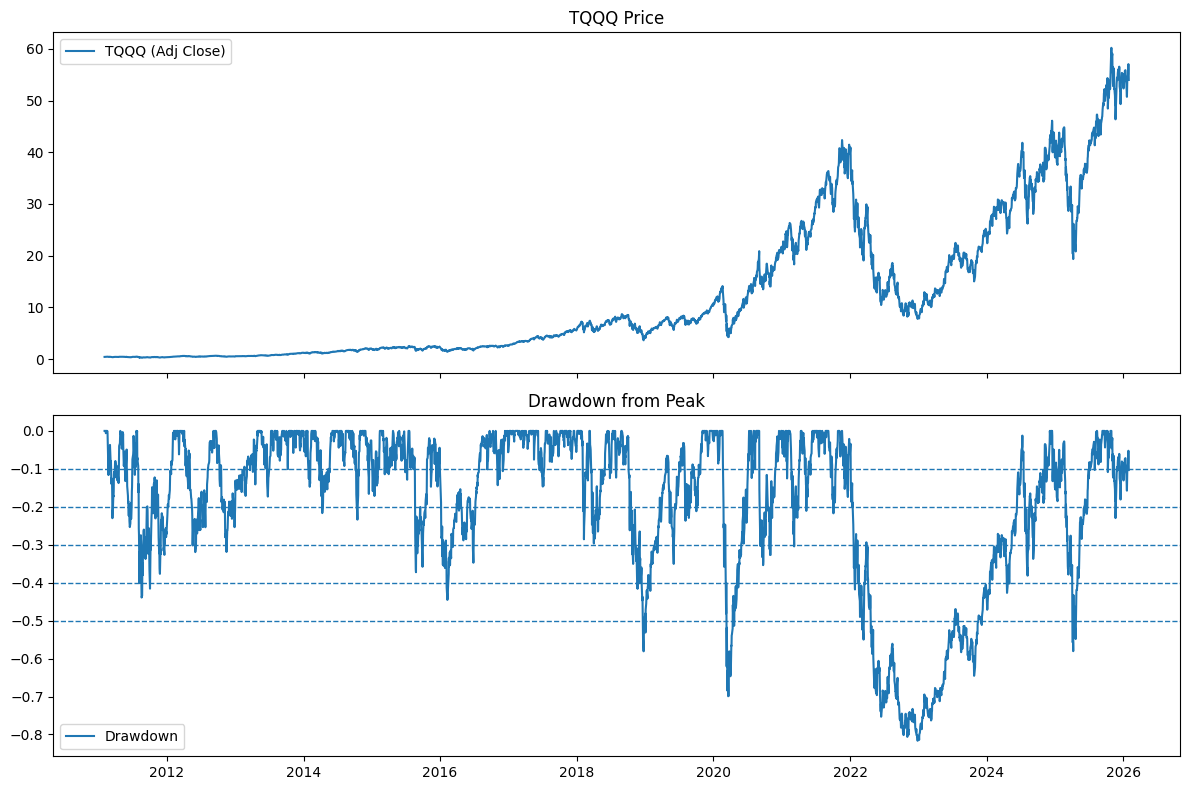

In [22]:
# Simple plot: price and drawdown from peak
import matplotlib.pyplot as plt

peak = prices.cummax()
drawdown = prices / peak - 1.0

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(prices.index, prices.values, label='TQQQ (Adj Close)')
ax[0].set_title('TQQQ Price')
ax[0].legend()

ax[1].plot(drawdown.index, drawdown.values, label='Drawdown')
for th in thresholds:
    ax[1].axhline(th - 1.0, linestyle='--', linewidth=1)
ax[1].set_title('Drawdown from Peak')
ax[1].legend()

plt.tight_layout()
plt.show()


In [23]:
# Display summary with Traditional Chinese column labels (unicode-escaped)
cn_map = {
    'trades_total': '\u4ea4\u6613\u7e3d\u6578',
    'trades_closed': '\u5df2\u5e73\u5009\u7b46\u6578',
    'trades_open': '\u672a\u5e73\u5009\u7b46\u6578',
    'close_rate': '\u5e73\u5009\u7387',
    'trades_per_year': '\u6bcf\u5e74\u4ea4\u6613\u6b21\u6578',
    'avg_return_multiple': '\u5e73\u5747\u5831\u916c\u500d\u6578',
    'median_return_multiple': '\u4e2d\u4f4d\u5831\u916c\u500d\u6578',
    'return_multiple_std': '\u5831\u916c\u500d\u6578\u6a19\u6e96\u5dee',
    'best_return_multiple': '\u6700\u4f73\u5831\u916c\u500d\u6578',
    'worst_return_multiple': '\u6700\u5dee\u5831\u916c\u500d\u6578',
    'avg_return_pct': '\u5e73\u5747\u5831\u916c\u767e\u5206\u6bd4',
    'median_return_pct': '\u4e2d\u4f4d\u5831\u916c\u767e\u5206\u6bd4',
    'win_rate': '\u52dd\u7387',
    'total_multiple_closed': '\u7e3d\u5831\u916c\u500d\u6578(\u5df2\u5e73\u5009)',
    'total_return_pct_closed': '\u7e3d\u5831\u916c\u767e\u5206\u6bd4(\u5df2\u5e73\u5009)',
    'avg_hold_days': '\u5e73\u5747\u6301\u6709\u5929\u6578',
    'median_hold_days': '\u4e2d\u4f4d\u6301\u6709\u5929\u6578',
    'max_hold_days': '\u6700\u9577\u6301\u6709\u5929\u6578',
    'min_hold_days': '\u6700\u77ed\u6301\u6709\u5929\u6578',
    'unrealized_multiple': '\u672a\u5be6\u73fe\u5831\u916c\u500d\u6578',
    'strategy_total_multiple': '\u7b56\u7565\u7e3d\u5831\u916c\u500d\u6578(\u542b\u672a\u5e73\u5009)',
    'strategy_cagr': '\u7b56\u7565\u5e74\u5316\u5831\u916c\u7387',
    'strategy_ann_vol': '\u7b56\u7565\u5e74\u5316\u6ce2\u52d5\u5ea6',
    'strategy_sharpe_0rf': '\u590f\u666e\u503c(\u7121\u98a8\u96aa\u5229\u7387=0)',
    'strategy_max_drawdown': '\u7b56\u7565\u6700\u5927\u56de\u64a4',
    'time_in_market': '\u5e02\u5834\u66dd\u96aa\u6bd4\u4f8b',
}
summary_df_cn = summary_df.rename(columns=cn_map)
summary_df_cn


,交易總數,已平倉筆數,未平倉筆數,平倉率,每年交易次數,平均報酬倍數,中位報酬倍數,報酬倍數標準差,最佳報酬倍數,最差報酬倍數,平均報酬百分比,中位報酬百分比,勝率,總報酬倍數(已平倉),總報酬百分比(已平倉),平均持有天數,中位持有天數,最長持有天數,最短持有天數,未實現報酬倍數,策略總報酬倍數(含未平倉),策略年化報酬率,策略年化波動度,夏普值(無風險利率=0),策略最大回撤,市場曝險比例
threshold,,,,,,,,,,,,,,,,,,,,,,,,,,
0.5000,4.0000,4.0000,0.0000,1.0000,0.2668,2.3121,2.2613,0.2053,2.6396,2.0860,1.3121,1.2613,1.0000,28.1425,27.1425,392.7500,224.0000,"1,003.0000",120.0000,NaN,28.1425,0.2493,0.3974,0.7596,-0.7404,0.2864
0.6000,6.0000,6.0000,0.0000,1.0000,0.4002,1.7811,1.7320,0.0922,1.9296,1.6930,0.7811,0.7320,1.0000,31.6698,30.6698,343.1667,207.0000,"1,042.0000",123.0000,NaN,31.6698,0.2592,0.4569,0.7354,-0.7482,0.3758
0.7000,10.0000,10.0000,0.0000,1.0000,0.6670,1.5178,1.4705,0.0839,1.6930,1.4401,0.5178,0.4705,1.0000,63.9429,62.9429,270.7000,161.0000,"1,049.0000",36.0000,NaN,63.9429,0.3196,0.5119,0.8008,-0.7482,0.4946
0.8000,19.0000,18.0000,1.0000,0.9474,1.2006,1.3134,1.2963,0.0523,1.4492,1.2572,0.3134,0.2963,1.0000,133.3814,132.3814,172.9444,91.5000,"1,056.0000",18.0000,1.1644,155.3040,0.4001,0.5418,0.8961,-0.7740,0.5813
0.9000,33.0000,32.0000,1.0000,0.9697,2.1344,1.1526,1.1461,0.0254,1.2348,1.1192,0.1526,0.1461,1.0000,93.3218,92.3218,116.1875,42.5000,"1,099.0000",6.0000,1.0120,94.4385,0.3544,0.5763,0.8189,-0.8126,0.6950
